# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'benh7'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

(2.0, -1.0)

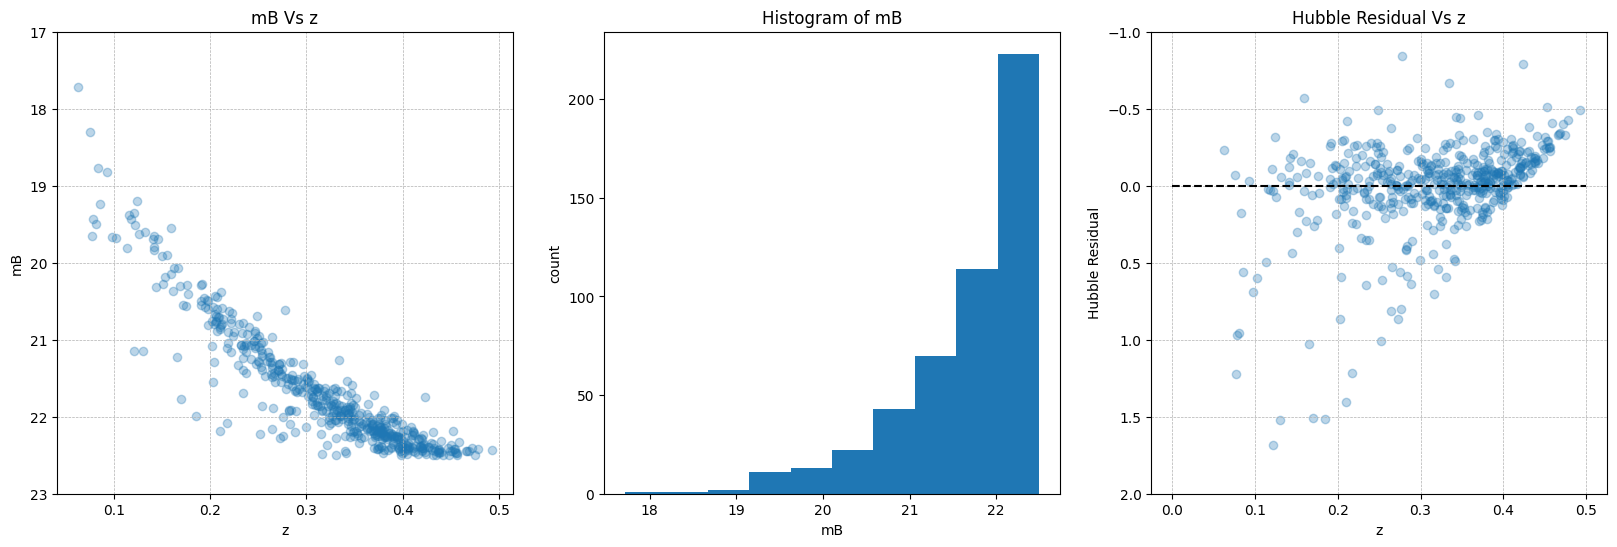

In [2]:
# Part 1: your work here
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u

plt.figure(figsize = (20, 6))
plt.subplot(1, 3, 1)
plt.scatter(z, m, alpha = .3)
plt.title('mB Vs z')
plt.xlabel('z')
plt.ylabel('mB')
plt.ylim([23, 17])

plt.grid(linestyle = '--', linewidth = 0.5)

plt.subplot(1, 3, 2)
plt.hist(m)
plt.title('Histogram of mB')
plt.xlabel('mB')
plt.ylabel('count')

plt.subplot(1, 3, 3)
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)
mu = cosmo.distmod(z).value
hubble_residual = m - (-19.30) - mu

plt.scatter(z, hubble_residual, alpha = .3)
plt.title('Hubble Residual Vs z')
plt.xlabel('z')
plt.ylabel('Hubble Residual')

plt.hlines(0, xmin = 0, xmax = .5, color = 'black', linestyle = '--')

plt.grid(linestyle = '--', linewidth = 0.5)
plt.ylim([2.0, -1.0])

Text(0.06, 13, 'Approximate Weighting Required for z^2 Proportionality')

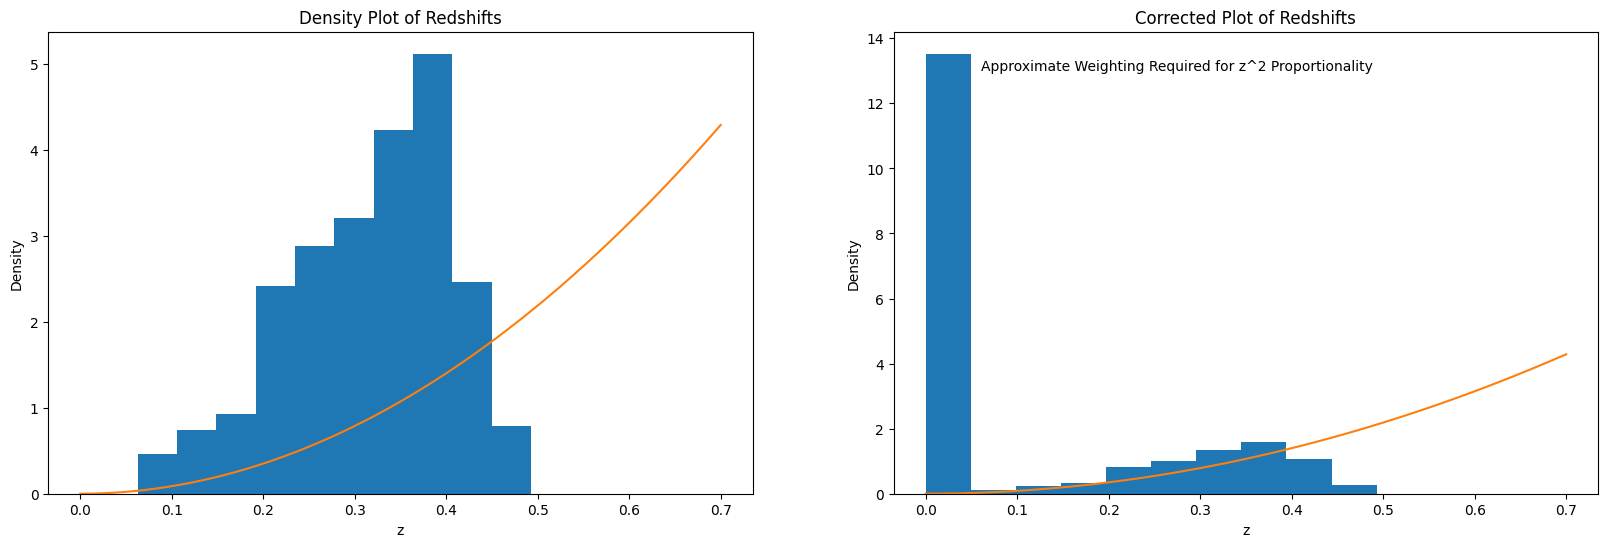

In [3]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.hist(z, density = True)
t = np.linspace(0, .7, 1000)
a = 3*t**2 / (.7**3 - .01**3)
plt.plot(t, a, label = 'Probability Function')
plt.xlabel('z')
plt.ylabel('Density')
plt.title('Density Plot of Redshifts')

plt.subplot(1, 2, 2)
zeros = np.zeros(1000)
test = np.concatenate([z, zeros])
plt.hist(test, density = True)
t = np.linspace(0, .7, 1000)
a = 3*t**2 / (.7**3 - .01**3)
plt.plot(t, a, label = 'Probability Function')
plt.xlabel('z')
plt.ylabel('Density')
plt.title('Corrected Plot of Redshifts')
plt.text(.06, 13, "Approximate Weighting Required for z^2 Proportionality")

The data is missing ~ 1000 supernovae!

In [4]:
np.percentile(z, [0, 50, 100])

array([0.062715 , 0.3306335, 0.492901 ])

In [5]:
P_below = (np.max(z)**3 - .01**3)/(.7**3 - .01**3)
Num_create = 500 / P_below
Num_create

np.float64(1432.146305916743)

In [6]:
def simulate(Om, f, rng, N):

    u = rng.random(size = N * 20)
    z = (u * (.7**3 - .01**3) + .01**3)**(1/3)
    
    MIa = rng.normal(-19.30, 0.12, size = round(f * N * 20))
    Mcc = rng.normal(-18.5, 0.5, size = N * 20 - round(f * N * 20))
    epsilon = rng.normal(0, 0.1, size = N * 20)

    M = np.concatenate([MIa, Mcc])
    rng.shuffle(M)

    cosmo = FlatLambdaCDM(H0 = 70, Om0 = Om)
    mu = cosmo.distmod(z).value

    mB = M + mu + epsilon
    mask = (mB < 22.5)

    z_keep = z[mask]
    mB_keep = mB[mask]

    idx = rng.choice(len(mB_keep), size = N, replace = False)

    return z_keep[idx], mB_keep[idx]

In [7]:
rng = np.random.default_rng(seed = 111626)
z_sim, m_sim, = simulate(.3, .3, rng, 500)

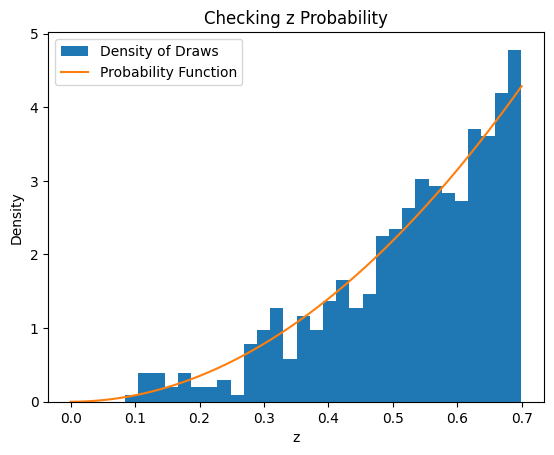

In [8]:
u = rng.random(size = 500)

ztest = (u * (.7**3 - .01**3) + .01**3)**(1/3)

plt.hist(ztest, bins = 30, density = True, label = 'Density of Draws')

t = np.linspace(0, .7, 1000)
a = 3*t**2 / (.7**3 - .01**3)

plt.plot(t, a, label = 'Probability Function')
plt.title('Checking z Probability')
plt.xlabel('z')
plt.ylabel('Density')
plt.legend()

In [9]:
np.max(m)

np.float64(22.497671)

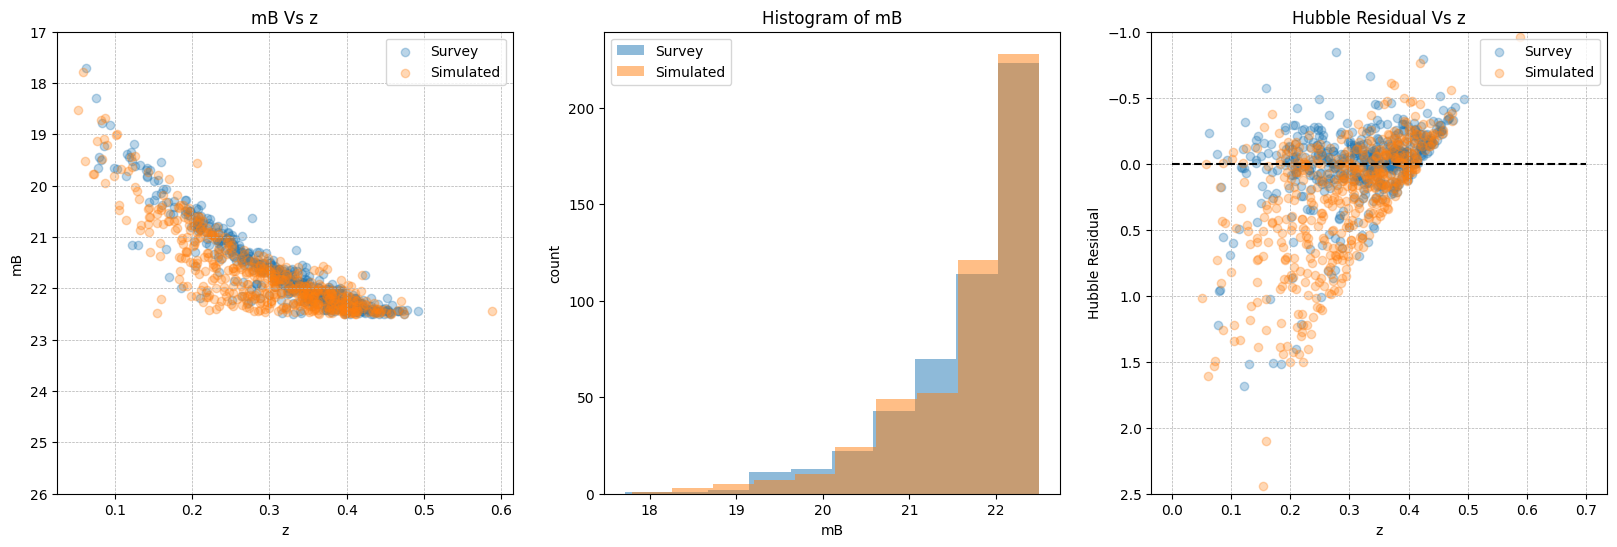

In [10]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 3, 1)
plt.scatter(z, m, alpha = .3, label = 'Survey')
plt.scatter(z_sim, m_sim, alpha = .3, label = 'Simulated')
plt.title('mB Vs z')
plt.xlabel('z')
plt.ylabel('mB')
plt.ylim([26, 17])

plt.grid(linestyle = '--', linewidth = 0.5)
plt.legend()

plt.subplot(1, 3, 2)
plt.hist(m, alpha = .5, label = 'Survey')
plt.hist(m_sim, alpha = .5, label = 'Simulated')
plt.title('Histogram of mB')
plt.xlabel('mB')
plt.ylabel('count')
plt.legend()

plt.subplot(1, 3, 3)
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)
mu = cosmo.distmod(z).value
hubble_residual = m - (-19.30) - mu

mu_sim = cosmo.distmod(z_sim).value
hubble_residual_sim = m_sim - (-19.30) - mu_sim

plt.scatter(z, hubble_residual, alpha = .3, label = 'Survey')
plt.scatter(z_sim, hubble_residual_sim, alpha = .3, label = 'Simulated')

plt.title('Hubble Residual Vs z')
plt.xlabel('z')
plt.ylabel('Hubble Residual')

plt.hlines(0, xmin = 0, xmax = .7, color = 'black', linestyle = '--')

plt.grid(linestyle = '--', linewidth = 0.5)
plt.ylim([2.5, -1.0])
plt.legend()

In [11]:
Om_grid = np.arange(0.05, 1.005, 0.005)
z_grid = np.linspace(0.01, 0.7, 500)

mu_table = np.zeros((len(Om_grid), len(z_grid)))

for i, Om in enumerate(Om_grid):

    cosmo = FlatLambdaCDM(H0 = 70, Om0 = Om)
    mu_table[i] = cosmo.distmod(z_grid).value

In [12]:
from scipy.interpolate import RegularGridInterpolator

mu_interp = RegularGridInterpolator((Om_grid, z_grid), mu_table)

In [13]:
count = 1
for i in range(10):
    for j in range(5):
        Om_test = 0.05 + .1 * i
        z_test = 0.02 + .1 * j
        
        cosmo = FlatLambdaCDM(H0 = 70, Om0 = Om_test)
        mu_true = cosmo.distmod(z_test).value
        mu_est = mu_interp([Om_test, z_test])[0]
    
        print(f'Run {count} true value: {mu_true}')
        print(f'Run {count} estimated value: {mu_est}')
        print(f'Difference: {np.abs(mu_true - mu_est)}')
        print('')

        count += 1

Run 1 true value: 34.70511561086323
Run 1 estimated value: 34.70421269946171
Difference: 0.0009029114015177697

Run 2 true value: 38.79011130861972
Run 2 estimated value: 38.7900751759463
Difference: 3.613267342217341e-05

Run 3 true value: 40.282142443400716
Run 3 estimated value: 40.282137393620616
Difference: 5.049780099852796e-06

Run 4 true value: 41.255905563154194
Run 4 estimated value: 41.25590227097413
Difference: 3.2921800610097307e-06

Run 5 true value: 41.9929588711449
Run 5 estimated value: 41.992955646530234
Difference: 3.2246146659531405e-06

Run 6 true value: 34.7018297924972
Run 6 estimated value: 34.7009268570263
Difference: 0.0009029354708971482

Run 7 true value: 38.76957019828026
Run 7 estimated value: 38.76953403563657
Difference: 3.616264369554756e-05

Run 8 true value: 40.24308179729805
Run 8 estimated value: 40.2430767357139
Difference: 5.06158415447544e-06

Run 9 true value: 41.19723926294195
Run 9 estimated value: 41.197235957803116
Difference: 3.305138832843

In [14]:
def simulate_interp(Om, f, rng, N):

    u = rng.random(size = N * 100)
    z = (u * (.7**3 - .01**3) + .01**3)**(1/3)
    epsilon = rng.normal(0, 0.1, size = N * 100)

    n_cc_parent = round(f * N * 100)
    n_ia_parent = N * 100 - n_cc_parent
    
    MIa = rng.normal(-19.30, 0.12, size = n_ia_parent)
    Mcc = rng.normal(-18.5, 0.5, size = n_cc_parent)
    
    M = np.concatenate([MIa, Mcc])
    is_cc = np.concatenate([np.zeros(n_ia_parent, dtype = bool), np.ones(n_cc_parent, dtype = bool)])
    
    perm = rng.permutation(len(M))
    
    M = M[perm]
    is_cc = is_cc[perm]

    mu = mu_interp(np.column_stack((np.full_like(z, Om), z) ) )

    mB = M + mu + epsilon
    mask = (mB < 22.5)

    z_keep = z[mask]
    mB_keep = mB[mask]

    idx = rng.choice(len(mB_keep), size = N, replace = False)
    
    cc_keep = is_cc[mask]

    n_cc_obs = round(f * N)
    n_ia_obs = N - n_cc_obs
    
    ia_idx = np.where(~cc_keep)[0]
    cc_idx = np.where(cc_keep)[0]
    
    final_cc = rng.choice(cc_idx, size=n_cc_obs, replace = False)
    final_ia = rng.choice(ia_idx, size = n_ia_obs, replace = False)

    idx = np.concatenate([final_cc, final_ia])
    rng.shuffle(idx)

    return z_keep[idx], mB_keep[idx]

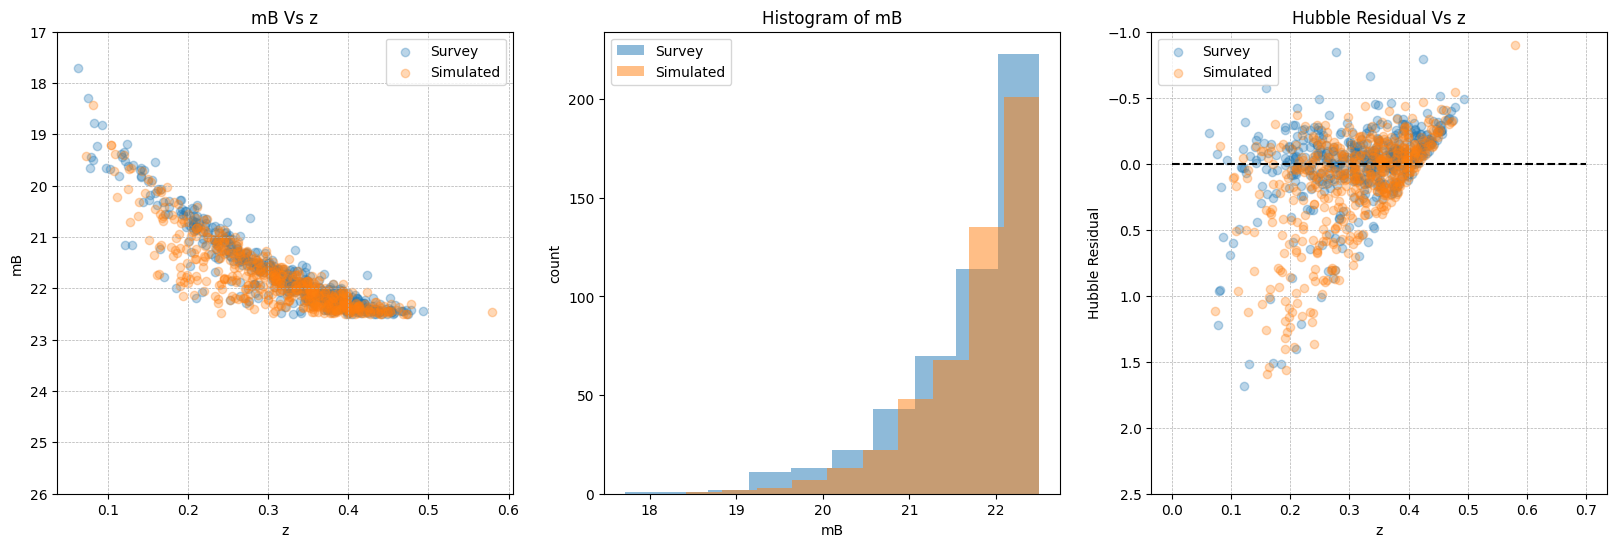

In [15]:
z_sim, m_sim, = simulate_interp(.3, .35, rng, 500)

plt.figure(figsize = (20, 6))
plt.subplot(1, 3, 1)
plt.scatter(z, m, alpha = .3, label = 'Survey')
plt.scatter(z_sim, m_sim, alpha = .3, label = 'Simulated')
plt.title('mB Vs z')
plt.xlabel('z')
plt.ylabel('mB')
plt.ylim([26, 17])

plt.grid(linestyle = '--', linewidth = 0.5)
plt.legend()

plt.subplot(1, 3, 2)
plt.hist(m, alpha = .5, label = 'Survey')
plt.hist(m_sim, alpha = .5, label = 'Simulated')
plt.title('Histogram of mB')
plt.xlabel('mB')
plt.ylabel('count')
plt.legend()

plt.subplot(1, 3, 3)
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)
mu = cosmo.distmod(z).value
hubble_residual = m - (-19.30) - mu

mu_sim = cosmo.distmod(z_sim).value
hubble_residual_sim = m_sim - (-19.30) - mu_sim

plt.scatter(z, hubble_residual, alpha = .3, label = 'Survey')
plt.scatter(z_sim, hubble_residual_sim, alpha = .3, label = 'Simulated')

plt.title('Hubble Residual Vs z')
plt.xlabel('z')
plt.ylabel('Hubble Residual')

plt.hlines(0, xmin = 0, xmax = .7, color = 'black', linestyle = '--')

plt.grid(linestyle = '--', linewidth = 0.5)
plt.ylim([2.5, -1.0])
plt.legend()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

*In my data, the survey shows a clear trend between z and mB; the further out the supernovae are, the dimmer they appear. When binned, the magnitudes create a skewed relationship that peaks at mB ~ 22.5. Then, looking at the hubble residuals, most of the data is centered about the zero line, however, there is a large population of supernova that are much closer and fainter than the main group.*

Mcc, MIa, Mi, f, and mui are all latent variables. The only thing that is data is mB and zi. f enters the graph as a latent variable that goes into Mi as it determines the fractional amount of each Mcc and MIa that will be seen. 

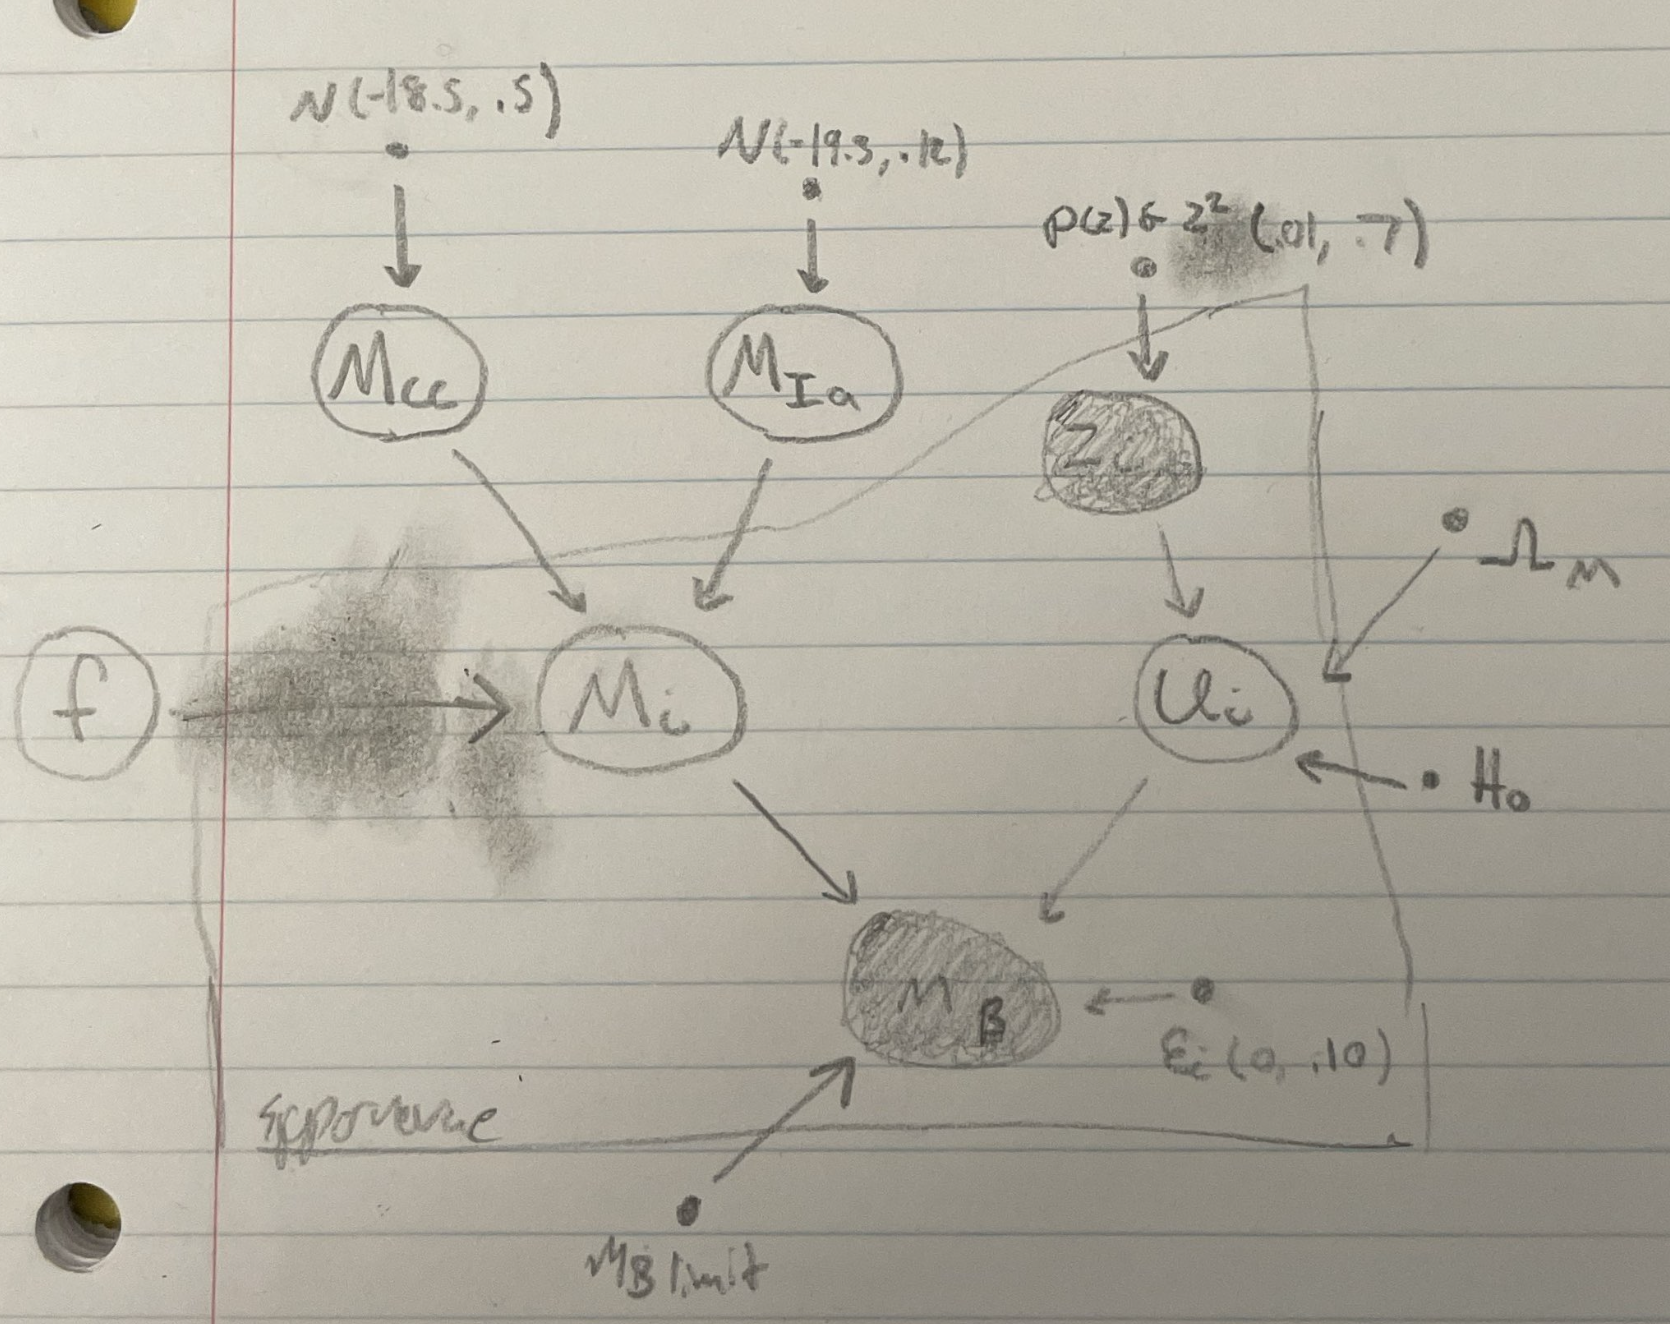

While looking through the data, I found what appears to be a mB cutoff in the data. This causes all of the data above ~22.5 mB to be cut from observation. To handle this, my simulation produces more supernova than needed from the family distributions. It then applies a mask to represent this limit. I then return a random 500 (taking care to return the same ratio of Mcc and MIa) back for viewing. 

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [16]:
# Part 2: your work here

In [17]:
import scipy

def chi2(Om_hat, zs, mB):
    cosmo = FlatLambdaCDM(H0 = 70, Om0 = Om_hat[0])
    
    mu = cosmo.distmod(zs).value
    return np.sum( (mB - (-19.30) - mu)**2 / (.12**2 + .10**2) )

In [18]:
result = scipy.optimize.minimize(chi2, .3, args = (z, m), method = 'Nelder-Mead')
result.x

array([0.34910156])

In [19]:
Om_grid = np.linspace(0.01, 1.0, 1000)

chi2_grid = np.array([chi2([Om], z, m) for Om in Om_grid])

In [20]:
chi2(result.x, z, m)

np.float64(1740.5550010922)

(0.33, 0.37)

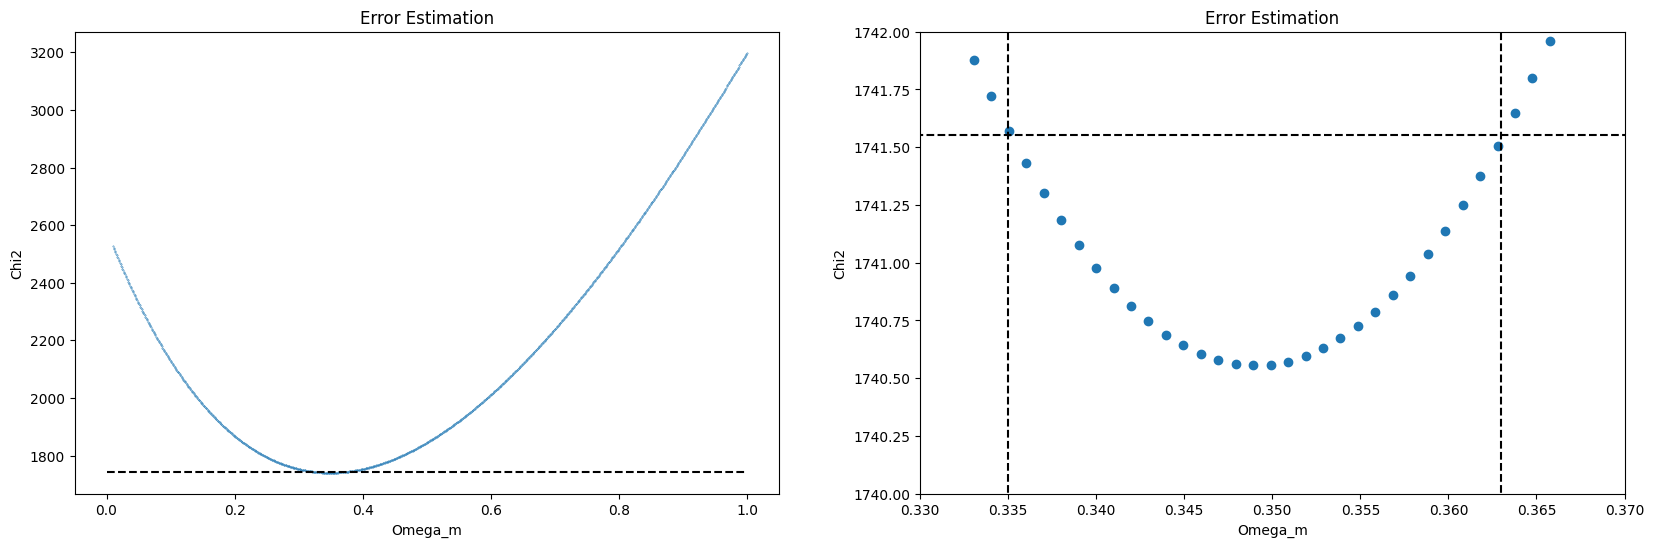

In [21]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.scatter(Om_grid, chi2_grid, s = .1)
plt.hlines(chi2(result.x, z, m) + 1, xmin = 0, xmax = 1, color = 'black', linestyle = '--')
plt.title('Error Estimation')
plt.xlabel('Omega_m')
plt.ylabel('Chi2')

plt.subplot(1, 2, 2)
plt.scatter(Om_grid, chi2_grid)
plt.hlines(chi2(result.x, z, m) + 1, xmin = 0, xmax = 1, color = 'black', linestyle = '--')
plt.vlines(.335, ymin = 1700, ymax = 1800, color = 'black', linestyle = '--')
plt.vlines(.363, ymin = 1700, ymax = 1800, color = 'black', linestyle = '--')

plt.title('Error Estimation')
plt.xlabel('Omega_m')
plt.ylabel('Chi2')

plt.ylim([1740, 1742])
plt.xlim([.33, .37])

**ANSWER (the naive fit, then why the impostors push it the way they do):**

*Naive Fit: .349 +- .014*

*The contaminents are fainter than the true type Ia supernovae. This causes Mu to be calculated as larger. Since the only parameter is Omega_m, this means Omega_m gets smaller. This makes the naive fit biased low as the supernovae aren't as bright as they were initially predicted to be.*

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

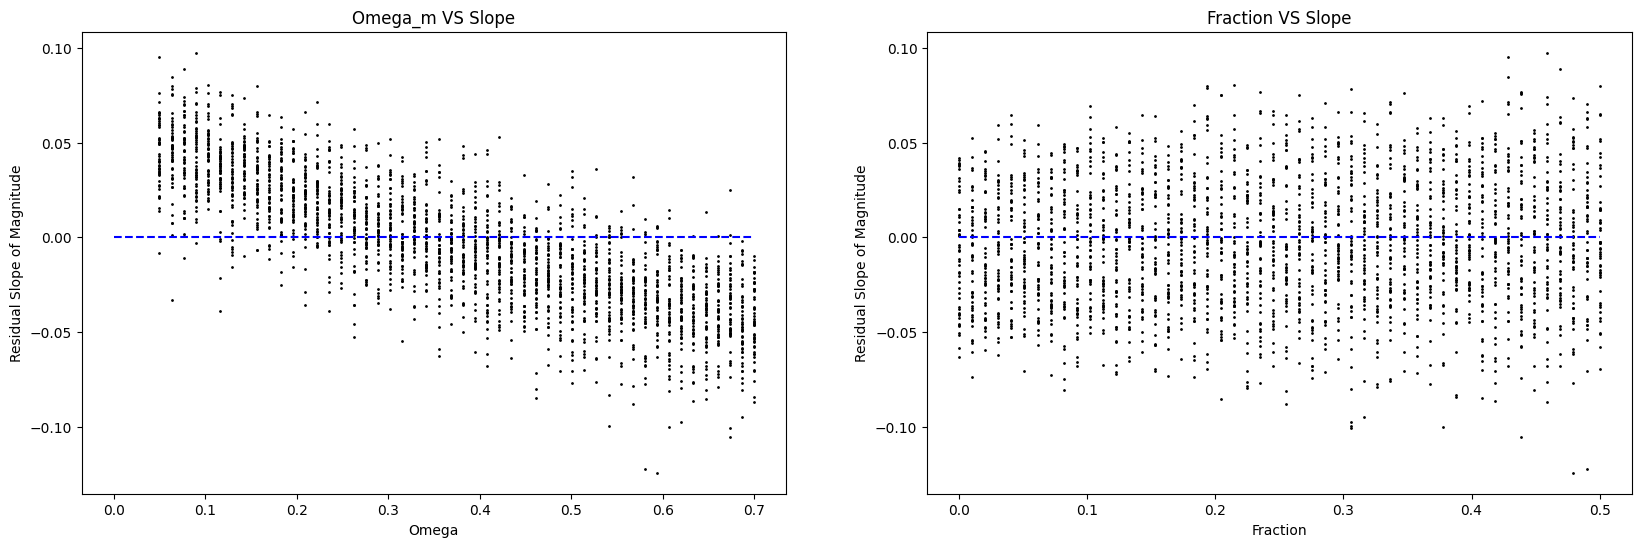

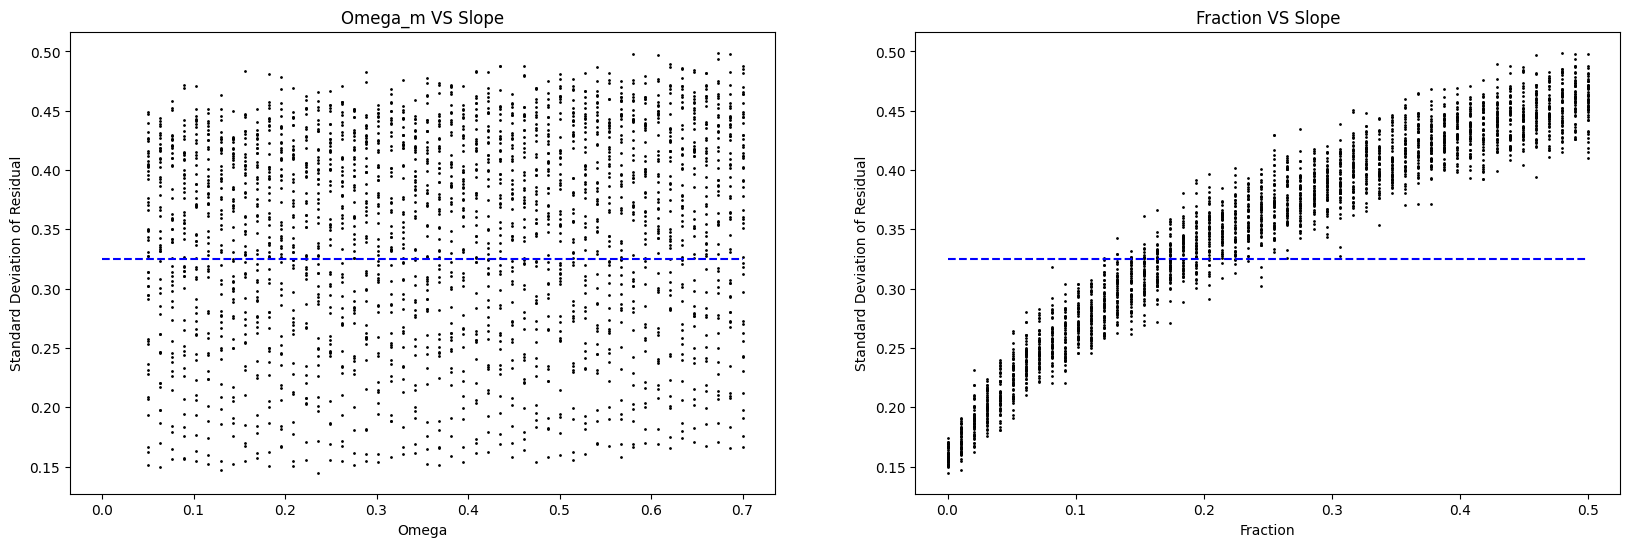

In [150]:
# Part 3: your work here

Om_test = np.linspace(0.05, .7, 50)
f_test = np.linspace(0.0, .5, 50)
plt.figure(figsize = (20, 6))
plt.figure(1)

plt.subplot(1, 2, 1)
plt.hlines(0, xmin = 0, xmax = .7, color = 'blue', linestyle = '--')
plt.subplot(1, 2, 2)
plt.hlines(0, xmin = 0, xmax = .5, color = 'blue', linestyle = '--')

for o in Om_test:
    for f in f_test:

        z_sim, m_sim, = simulate_interp(o, f, rng, 500)
        r = m_sim + 19.3 - cosmo.distmod(z_sim).value
        slope = np.polyfit(m_sim, r, 1)[0]
        
        plt.subplot(1, 2, 1)
        plt.scatter(o, slope, color = 'black', s = 1)
        plt.xlabel('Omega')
        plt.ylabel('Residual Slope of Magnitude')
        plt.title('Omega_m VS Slope')
    
        plt.subplot(1, 2, 2)
        plt.scatter(f, slope, color = 'black', s = 1)
        plt.xlabel('Fraction')
        plt.ylabel('Residual Slope of Magnitude')
        plt.title('Fraction VS Slope')

plt.figure(figsize = (20, 6))
plt.figure(2)


plt.subplot(1, 2, 1)
plt.hlines(.325, xmin = 0, xmax = .7, color = 'blue', linestyle = '--')
plt.subplot(1, 2, 2)
plt.hlines(.325, xmin = 0, xmax = .5, color = 'blue', linestyle = '--')

for o in Om_test:
    for f in f_test:
        
        z_sim, m_sim, = simulate_interp(o, f, rng, 500)
        r = m_sim + 19.3 - cosmo.distmod(z_sim).value
        s = np.std(r)
        
        plt.subplot(1, 2, 1)
        plt.scatter(o, s, color = 'black', s = 1)
        plt.xlabel('Omega')
        plt.ylabel('Standard Deviation of Residual')
        plt.title('Omega_m VS Slope')
    
        plt.subplot(1, 2, 2)
        plt.scatter(f, s, color = 'black', s = 1)
        plt.xlabel('Fraction')
        plt.ylabel('Standard Deviation of Residual')
        plt.title('Fraction VS Slope')

In [151]:
r_data = m + 19.3 - cosmo.distmod(z).value

S1_data = np.polyfit(m, r_data, 1)[0]
S2_data = np.std(r_data)

print(S1_data)
print(S2_data)

-0.016871909201583473
0.2924793532944161


In [152]:
n_sims = 50_000

Om_draws = rng.uniform(0.05, 0.7, n_sims)
f_draws = rng.uniform(0.0, 0.5, n_sims)

S1 = np.empty(n_sims)
S2 = np.empty(n_sims)

for i in range(n_sims):
    z_sim, m_sim = simulate_interp(Om_draws[i], f_draws[i], rng, 500)

    r = (m_sim + 19.3 - cosmo.distmod(z_sim).value)
    S1[i] = np.polyfit(m_sim, r, 1)[0]
    S2[i] = np.std(r)

In [153]:
sigma1 = np.max(S1) - np.min(S1)
sigma2 = np.max(S2) - np.min(S2)

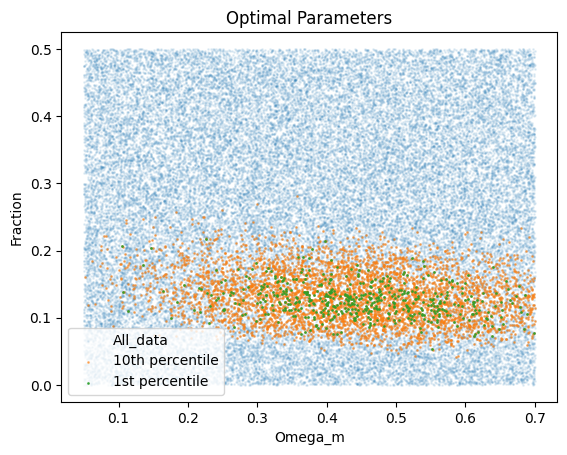

In [154]:
distance = np.sqrt( ((S1 - S1_data)/sigma1)**2 + ((S2 - S2_data)/sigma2)**2 )
eps1 = np.percentile(distance, 10)
eps2 = np.percentile(distance, 1)

keep1 = distance < eps1
keep2 = distance < eps2

plt.scatter(Om_draws, f_draws, s = 1, alpha = 0.1, label = 'All_data')
plt.scatter(Om_draws[keep1], f_draws[keep1], s = 1, alpha = 0.5, label = '10th percentile')
plt.scatter(Om_draws[keep2], f_draws[keep2], s = 1, alpha = 0.8, label = '1st percentile')
plt.xlabel('Omega_m')
plt.ylabel('Fraction')
plt.title('Optimal Parameters')

plt.legend()

<Figure size 640x480 with 0 Axes>

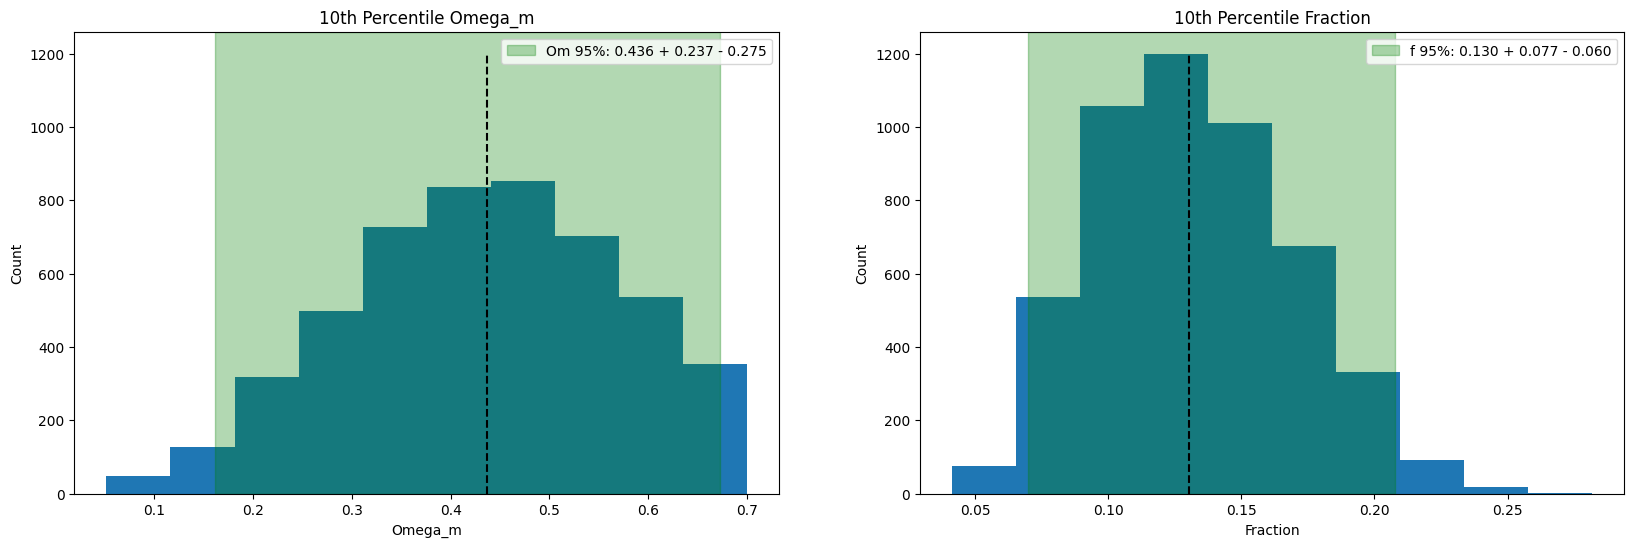

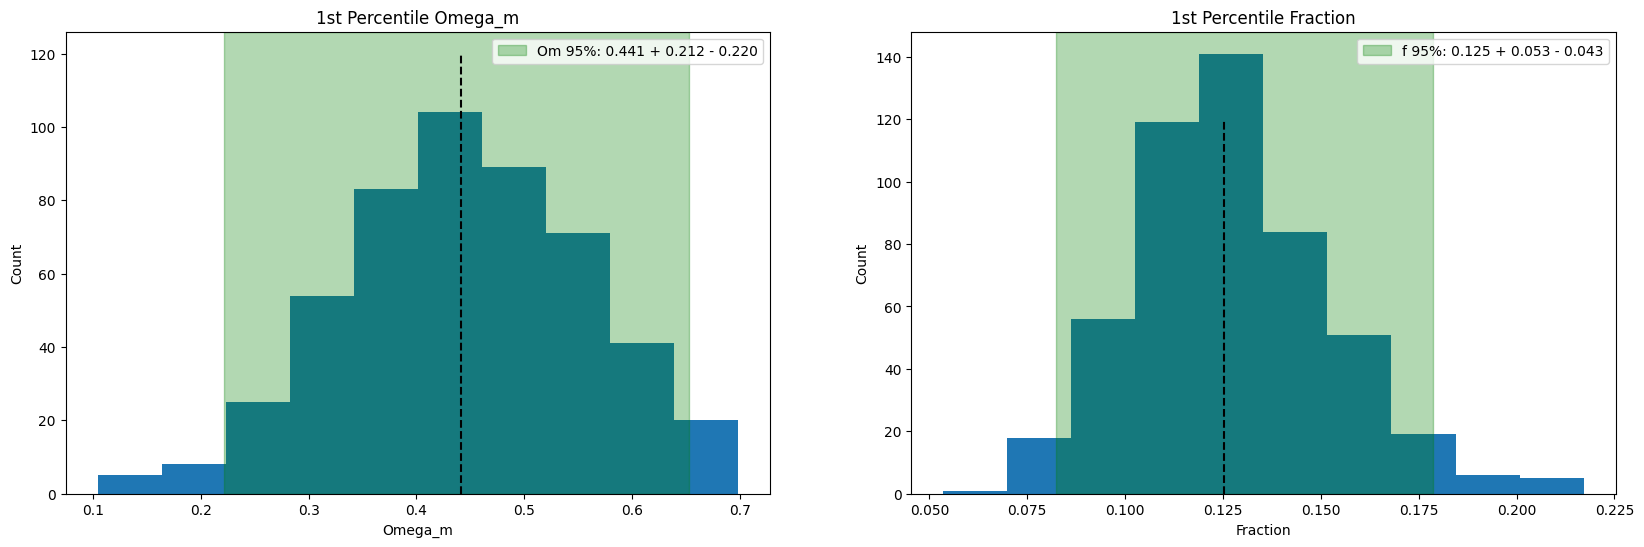

In [155]:
plt.figure(1)
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.title('10th Percentile Omega_m')
plt.xlabel('Omega_m')
plt.ylabel('Count')
plt.hist(Om_draws[keep1])

lo, med, hi = np.percentile(Om_draws[keep1], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'Om 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 1200, color = 'black', linestyle = '--')

plt.legend()

plt.subplot(1, 2, 2)
plt.hist(f_draws[keep1])
plt.title('10th Percentile Fraction')
plt.xlabel('Fraction')
plt.ylabel('Count')

lo, med, hi = np.percentile(f_draws[keep1], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'f 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 1200, color = 'black', linestyle = '--')

plt.legend()

plt.figure(2)
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.title('1st Percentile Omega_m')
plt.xlabel('Omega_m')
plt.ylabel('Count')
plt.hist(Om_draws[keep2])

lo, med, hi = np.percentile(Om_draws[keep2], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'Om 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 120, color = 'black', linestyle = '--')

plt.legend()

plt.subplot(1, 2, 2)
plt.hist(f_draws[keep2])
plt.title('1st Percentile Fraction')
plt.xlabel('Fraction')
plt.ylabel('Count')

lo, med, hi = np.percentile(f_draws[keep2], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'f 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 120, color = 'black', linestyle = '--')

plt.legend()

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

*Summaries: 
Residual Slope of Magnitude: This tracks omega. Changing mB directly changes the residual value pushing the slope up or down. The fraction won't affect this however as the fraction adds scatter about the line rather a unified trend in a particular direction.
Residual Scatter: Having a larger fraction of contaminents makes the residual width thicker as it gets spread out by the differences in the supernovae. Omega however, isn't really affected by this scatter as the they set the r value not its scatter.*

95% Intervals:
Omega_m: .440 +(.213) or -(.219)
f: .126 +(.056) or -(.042)

Epsilon 1: 10th percentile
Epsilon 2: 1st percentile

Final Epsilon Range: .440 +(.213) or -(.219)

Comparison: .440 +(.213) or -(.219) is a much wider interval than the naive fit of .349 +- .014. The entire range of the naive Omega_m fit could rest inside the range of the ABC method. While the assumption that the uncertainties are gaussian is met by the survey, the naive fit assumes that the entire population resides within the survey. This creates a biased Omega_m with a very narrow uncertianity. The ABC method however searches a wide span of Omega_m-Fraction space to test which values are possible. This alternate method searches a much wider area so it creates much wider errorbars. 

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

In [116]:
# Part 4: your work here

(17.0, 23.0)

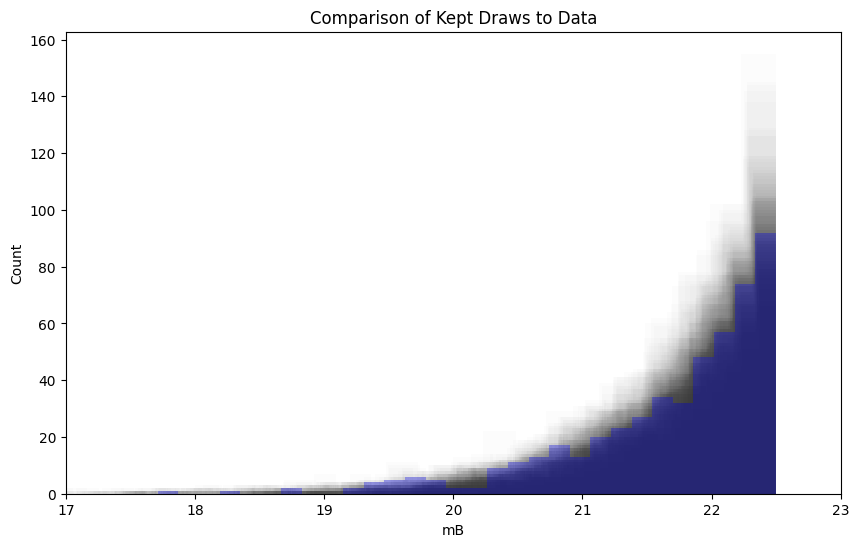

In [131]:
plt.figure(figsize = (10, 6))
plt.title('Comparison of Kept Draws to Data')
plt.xlabel('mB')
plt.ylabel('Count')

for i in range(100):
    z_sim, m_sim, = simulate_interp(Om_draws[keep2][i], f_draws[keep2][i], rng, 500)
    plt.hist(m_sim, color = 'black', alpha = .01, bins = 30)

plt.hist(m, alpha = .3, color = 'blue', bins = 30)
plt.xlim([17, 23])

In [135]:
coverage_Om = []
coverage_f = []

test_idx = rng.choice(len(Om_draws), size = 10_000, replace = False)
for idx in test_idx:

    S1_obs = S1[idx]
    S2_obs = S2[idx]

    Om_true = Om_draws[idx]
    f_true = f_draws[idx]

    mask = np.ones(len(S1), dtype = bool)
    mask[idx] = False
    distance = np.sqrt(((S1[mask] - S1_obs)/sigma1)**2 + ((S2[mask] - S2_obs)/sigma2)**2)
    
    eps = np.percentile(distance, 1)
    keep = distance < eps

    Om_lo, Om_hi = np.percentile(Om_draws[mask][keep], [2.5, 97.5])
    f_lo, f_hi = np.percentile(f_draws[mask][keep], [2.5, 97.5])

    coverage_Om.append(Om_lo <= Om_true <= Om_hi)
    coverage_f.append(f_lo <= f_true <= f_hi)

In [136]:
print(np.sum(coverage_Om))
print(np.sum(coverage_f))

9529
9622


Text(0.5, 1.0, 'Coverage of 95% ABC intervals')

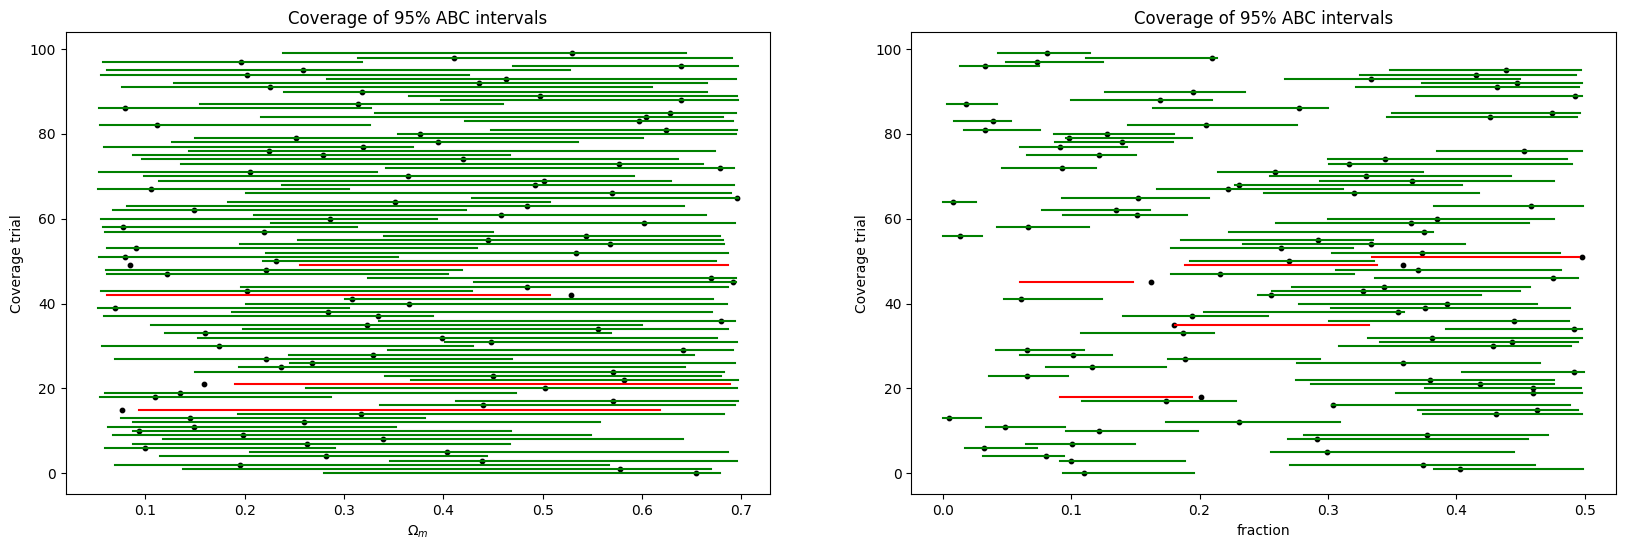

In [137]:
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)

for i, idx in enumerate(test_idx[:100]):

    S1_obs = S1[idx]
    S2_obs = S2[idx]

    mask = np.ones(len(S1), dtype = bool)
    mask[idx] = False

    distance = np.sqrt(((S1[mask] - S1_obs)/sigma1)**2 + ((S2[mask] - S2_obs)/sigma2)**2)

    keep = distance < np.percentile(distance, 1)

    lo, hi = np.percentile(Om_draws[mask][keep], [2.5, 97.5])

    truth = Om_draws[idx]

    color = 'green' if lo <= truth <= hi else 'red'

    plt.plot([lo, hi], [i, i], color = color)
    plt.scatter(truth, i, color = 'black', s = 10)

plt.xlabel(r'$\Omega_m$')
plt.ylabel('Coverage trial')
plt.title('Coverage of 95% ABC intervals')

plt.subplot(1, 2, 2)

for i, idx in enumerate(test_idx[:100]):

    S1_obs = S1[idx]
    S2_obs = S2[idx]

    mask = np.ones(len(S1), dtype = bool)
    mask[idx] = False

    distance = np.sqrt(((S1[mask] - S1_obs)/sigma1)**2 + ((S2[mask] - S2_obs)/sigma2)**2)

    keep = distance < np.percentile(distance, 1)

    lo, hi = np.percentile(f_draws[mask][keep], [2.5, 97.5])

    truth = f_draws[idx]

    color = 'green' if lo <= truth <= hi else 'red'

    plt.plot([lo, hi],[i, i], color = color)
    plt.scatter(truth, i, color='black', s = 10)

plt.xlabel('fraction')
plt.ylabel('Coverage trial')
plt.title('Coverage of 95% ABC intervals')

**ANSWER (the check, the coverage, and the assumption):**

*When plotting simulations that were kept with epsilon, they overlaid right ontop of my survey data. The kept histograms have the same shape and cutoff seen in my survey and do not have significant deviations from the survey.*

(17.0, 23.0)

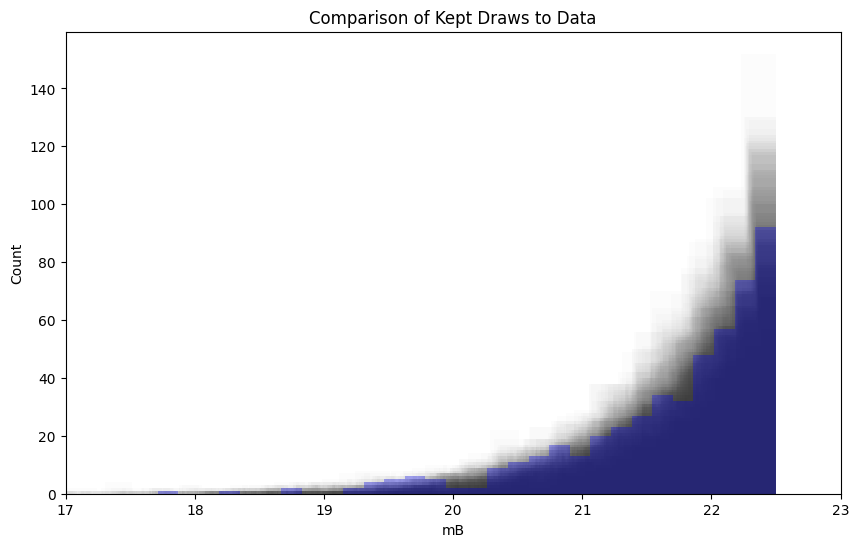

In [138]:
plt.figure(figsize = (10, 6))
plt.title('Comparison of Kept Draws to Data')
plt.xlabel('mB')
plt.ylabel('Count')

for i in range(100):
    z_sim, m_sim, = simulate_interp(Om_draws[keep2][i], f_draws[keep2][i], rng, 500)
    plt.hist(m_sim, color = 'black', alpha = .01, bins = 30)

plt.hist(m, alpha = .3, color = 'blue', bins = 30)
plt.xlim([17, 23])

Coverage of 10_000 points:

Omega_m: 95.29%

Fraction: 96.22%

Assumption: My simulator assumes there is a hard mB cutoff at 22.5 magnitudes. A real survey would instead detect objects based off a detection probability (brighter objects are more likely while fainter objects are much less likely). Since this cuts off dim supernovae this makes my simulations artificially brighter. This would create a bias towards a larger omega_m if it wasn't handled as the objects would appear brighter than they should be.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

*I used Copilot to help debug my code, learn content, compare options, and generate code segments. The Ai got mixed up on variables and also strategies for handling the supernovae.*

**REFLECTION:**

*Initially, the Ai model felt that using a Bernoulli distribution was a part of the assignment and hallucinated this by assuming that I was using a mixture model to describe supernovae rather than an ABC method. This would've taken me down the completely wrong track as an ABC simulation is a liklihood free method; using a mixture model is inheriently a liklihood model and would've required I use different tactics than this lab lays out. It also got confused by the fraction convention and couldn't decide where the fraction variable should go. If I had miss placed which values were getting multiplied by f vs 1 - f then my fractional values would've come out backwards. When I started comparing z values, the Ai could tell that the distribution wasn't the same shape as what the distribution would look like for 500 supernovae. However, was not able to tell that there was a hard cutoff in the data. If I hadn't visually checked whether the hardcut off was the issue by simulating the true proportion of lightcurves that would make the distribution proportional to z^2, then I would've resulted in a method that wouldn't have handled the changes to the survey. This could've lead to potential bias down the road later. The Ai also initially catch that my simulation (since it was chooseing random supernovae) was changing my proportion of type Ia to type cc sueprnovae. It wasn't until I began looking at summary statistics that I compared the final fraction to the inputed fraction that I realized the values were off and that they would need to be handled within the simulator.*

**VERIFICATION PLAN:**

*For my verification plan, I am simulating my own survey. A failure for this would be if my ABC method cannot recover the true parameters within its 95% bounds.*

In [144]:
z_sim, m_sim, = simulate_interp(.35, .25, rng, 500)
r_data = m_sim + 19.3 - cosmo.distmod(z_sim).value

S1_data = np.polyfit(m_sim, r_data, 1)[0]
S2_data = np.std(r_data)

In [145]:
n_sims = 50_000

Om_draws = rng.uniform(0.05, 0.7, n_sims)
f_draws = rng.uniform(0.0, 0.5, n_sims)

S1 = np.empty(n_sims)
S2 = np.empty(n_sims)

for i in range(n_sims):
    z_sim, m_sim = simulate_interp(Om_draws[i], f_draws[i], rng, 500)

    r = (m_sim + 19.3 - cosmo.distmod(z_sim).value)
    S1[i] = np.polyfit(m_sim, r, 1)[0]
    S2[i] = np.std(r)

In [146]:
sigma1 = np.max(S1) - np.min(S1)
sigma2 = np.max(S2) - np.min(S2)

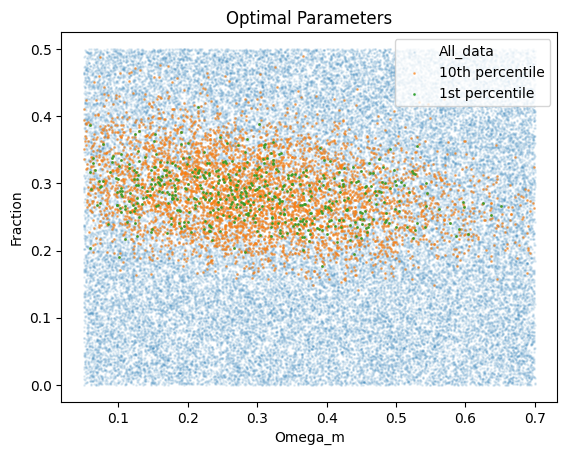

In [147]:
distance = np.sqrt( ((S1 - S1_data)/sigma1)**2 + ((S2 - S2_data)/sigma2)**2 )
eps1 = np.percentile(distance, 10)
eps2 = np.percentile(distance, 1)

keep1 = distance < eps1
keep2 = distance < eps2

plt.scatter(Om_draws, f_draws, s = 1, alpha = 0.1, label = 'All_data')
plt.scatter(Om_draws[keep1], f_draws[keep1], s = 1, alpha = 0.5, label = '10th percentile')
plt.scatter(Om_draws[keep2], f_draws[keep2], s = 1, alpha = 0.8, label = '1st percentile')
plt.xlabel('Omega_m')
plt.ylabel('Fraction')
plt.title('Optimal Parameters')

plt.legend()

<Figure size 640x480 with 0 Axes>

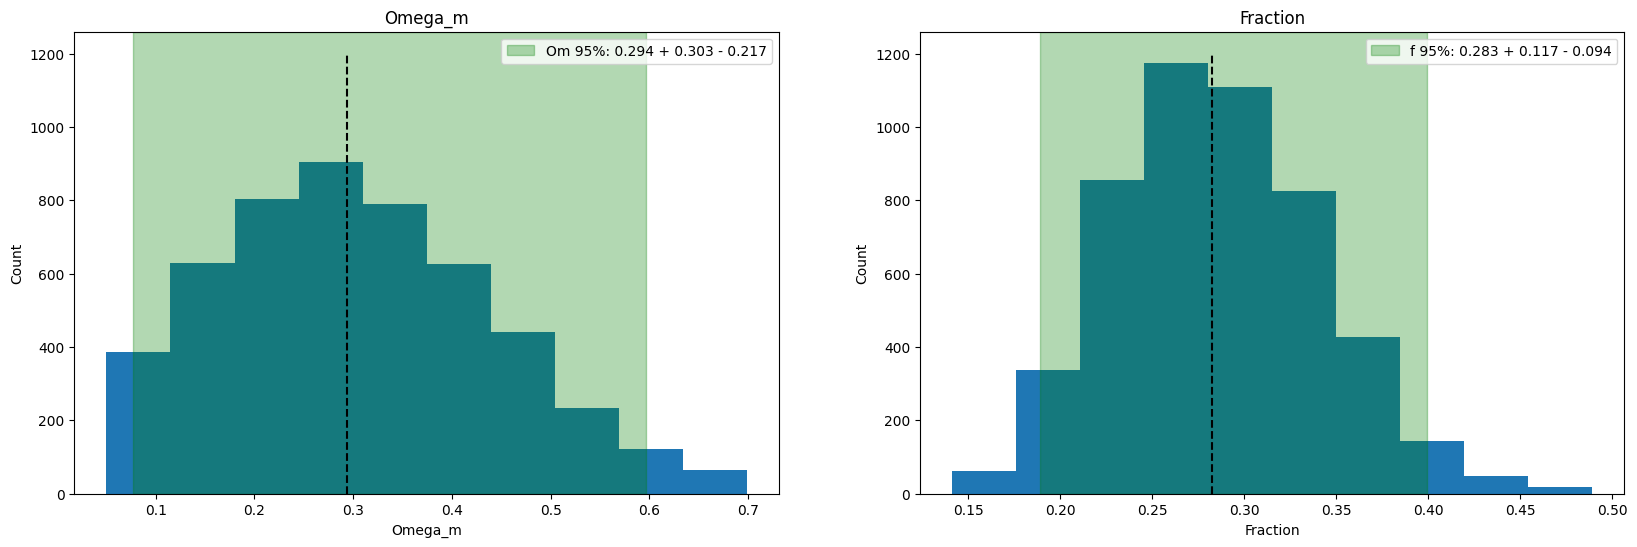

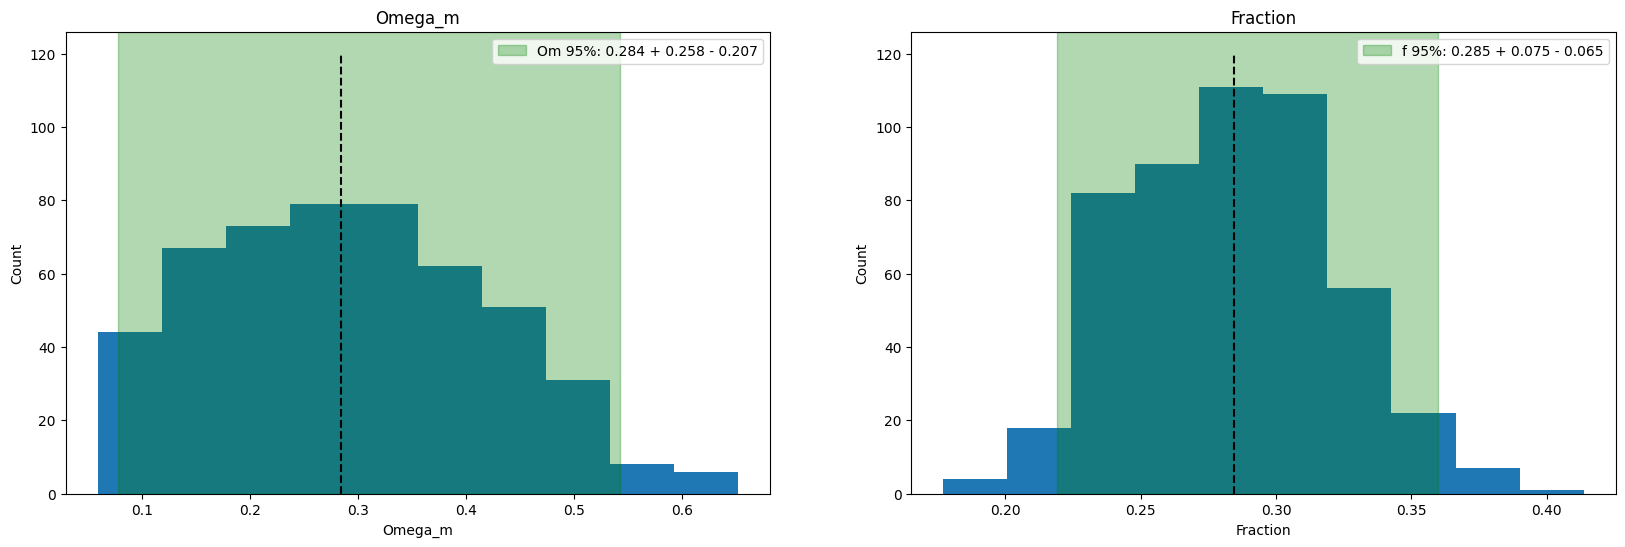

In [148]:
plt.figure(1)
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.title('Omega_m')
plt.xlabel('Omega_m')
plt.ylabel('Count')
plt.hist(Om_draws[keep1])

lo, med, hi = np.percentile(Om_draws[keep1], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'Om 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 1200, color = 'black', linestyle = '--')

plt.legend()

plt.subplot(1, 2, 2)
plt.hist(f_draws[keep1])
plt.title('Fraction')
plt.xlabel('Fraction')
plt.ylabel('Count')

lo, med, hi = np.percentile(f_draws[keep1], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'f 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 1200, color = 'black', linestyle = '--')

plt.legend()

plt.figure(2)
plt.figure(figsize = (20, 6))
plt.subplot(1, 2, 1)
plt.title('Omega_m')
plt.xlabel('Omega_m')
plt.ylabel('Count')
plt.hist(Om_draws[keep2])

lo, med, hi = np.percentile(Om_draws[keep2], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'Om 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 120, color = 'black', linestyle = '--')

plt.legend()

plt.subplot(1, 2, 2)
plt.hist(f_draws[keep2])
plt.title('Fraction')
plt.xlabel('Fraction')
plt.ylabel('Count')

lo, med, hi = np.percentile(f_draws[keep2], [2.5, 50, 97.5])
plt.axvspan(lo, hi, color = 'green', alpha = .3, label = f'f 95%: {med:.3f} + {(hi - med):.3f} - {(med - lo):.3f}')
plt.vlines(med, ymin = 0, ymax = 120, color = 'black', linestyle = '--')

plt.legend()

After running my ABC simulation, I recover values who's 95% percentile bounds include the true values. As my simulator can recover the true values, it passed this verification step. 